# Import packages :

In [1]:
import utils
from utils import *
import importlib
from torchvision.transforms import ToTensor

from sklearn.model_selection import train_test_split

from torch.utils.data import random_split

In [2]:
reset_val_dir()

# Dataset and Data Augmentation :

In [3]:
import os

all_filenames = [f for f in os.listdir("../dataset_project_iapr2025/train") if f.endswith(('.JPG'))]

train_filenames, val_filenames = train_test_split(all_filenames, test_size=0.2, random_state=42)

In [4]:
class YoloDetectionAugmentedDataset(torch.utils.data.Dataset):
    def __init__(self, image_filenames, image_dir, label_dir, anchors,
                 transform, num_augmentations=2,
                 resized_img_width=576, resized_img_height=384,
                 grid_width=18, grid_height=12,
                 num_classes=13, ignore_iou_thresh=0.8):
        """
        Create a fixed dataset with N augmentations per image.

        Args:
            image_filenames: list of image file names
            image_dir: path to directory with images
            label_dir: path to directory with YOLO-format labels (.txt)
            anchors: list of anchor box sizes
            transform: YoloCompatibleTransform (with train=True)
            num_augmentations: number of augmented copies per image
        """
        self.anchors = torch.tensor(anchors)
        self.num_anchors = len(anchors)
        self.num_classes = num_classes
        self.grid_width = grid_width
        self.grid_height = grid_height
        self.ignore_iou_thresh = ignore_iou_thresh

        self.original_transform = YoloCompatibleTransform(
            resized_img_width=resized_img_width,
            resized_img_height=resized_img_height,
            train=False
        )
        self.augmenting_transform = transform
        self.data = []

        print("Preprocessing images with fixed augmentations...")
        for filename in tqdm(image_filenames):
            label_filename = os.path.splitext(filename)[0] + ".txt"
            label_path = os.path.join(label_dir, label_filename)
            bboxes = np.roll(np.loadtxt(label_path, delimiter=" ", ndmin=2), 4, axis=1).tolist()

            img_path = os.path.join(image_dir, filename)
            image = np.array(Image.open(img_path).convert("RGB"))

            transforms_all = [self.original_transform] + [self.augmenting_transform] * num_augmentations
            for tf in transforms_all:
                transformed = tf(image, bboxes)
                image_tensor = transformed["image"]
                transformed_bboxes = transformed["bboxes"]
                target_tensor = self.encode_targets(transformed_bboxes)
                self.data.append((image_tensor, target_tensor))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    def encode_targets(self, bboxes):
        """
        Convert bounding boxes into YOLO-style target tensor.
        Format: (num_anchors, grid_height, grid_width, 6)
        """
        target = torch.zeros((self.num_anchors, self.grid_height, self.grid_width, 6))
        for box in bboxes:
            iou_anchors = iou(torch.tensor(box[2:4]), self.anchors, is_pred=False)
            anchor_indices = iou_anchors.argsort(descending=True)

            x, y, w, h, cls = box
            has_anchor = False
            for anchor_idx in anchor_indices:
                i = min(int(self.grid_height * y), self.grid_height - 1)
                j = min(int(self.grid_width * x), self.grid_width - 1)

                if not has_anchor:
                    target[anchor_idx, i, j, 0] = 1
                    x_cell = self.grid_width * x - j
                    y_cell = self.grid_height * y - i
                    w_cell = w * self.grid_width
                    h_cell = h * self.grid_height
                    target[anchor_idx, i, j, 1:5] = torch.tensor([x_cell, y_cell, w_cell, h_cell])
                    target[anchor_idx, i, j, 5] = int(cls)
                    has_anchor = True
                elif iou_anchors[anchor_idx] > self.ignore_iou_thresh:
                    target[anchor_idx, i, j, 0] = -1
        return target

In [8]:
# Path to your dataset folder

# Get all image filenames (JPG, JPEG, PNG, etc.)
image_filenames = [f for f in os.listdir("../dataset_project_iapr2025/train") if f.endswith(('.JPG'))]

# Optional: fix the seed for reproducibility
np.random.seed(42)

# Split into train and validation sets (e.g., 80/20 split)
train_filenames, val_filenames = train_test_split(
    image_filenames, test_size=0.5, random_state=42
)

train_dataset = YoloDetectionAugmentedDataset(
	image_filenames=train_filenames,
	image_dir="../dataset_project_iapr2025/train",
	label_dir="./labels",
    anchors=ANCHORS,
    transform=YoloCompatibleTransform(train=True),
    num_augmentations=2
)

val_dataset = YoloDetectionAugmentedDataset(
	image_filenames=val_filenames,
	image_dir="../dataset_project_iapr2025/train",
	label_dir="./labels",
    anchors=ANCHORS,
    transform=YoloCompatibleTransform(train=False),
    num_augmentations=0
)

def yolo_collate_fn(batch):
    images, targets = zip(*batch)  # Unzips list of tuples
    images = torch.stack(images)
    targets = torch.stack(targets)
    return images, targets

train_loader = torch.utils.data.DataLoader(
	train_dataset, batch_size=4, shuffle=True, collate_fn=yolo_collate_fn)

val_loader = torch.utils.data.DataLoader(
	val_dataset, batch_size=4, shuffle=True, collate_fn=yolo_collate_fn)


# dataloader = torch.utils.data.DataLoader(
#     dataset, batch_size=4, shuffle=True, collate_fn=lambda x: tuple(zip(*x))
# )

Preprocessing images with fixed augmentations...


100%|██████████| 45/45 [00:40<00:00,  1.10it/s]


Preprocessing images with fixed augmentations...


100%|██████████| 45/45 [00:22<00:00,  2.02it/s]


In [63]:
# importlib.reload(utils)

# train_transform = YoloCompatibleTransform(resized_img_width=RESIZED_IMG_WIDTH, 
# 										  resized_img_height=RESIZED_IMG_HEIGHT, train=True)
# test_transform = YoloCompatibleTransform(resized_img_width=RESIZED_IMG_WIDTH, 
# 										 resized_img_height=RESIZED_IMG_HEIGHT, train=False)


# # Read full CSV that has 2 columns: image name (LXXXXXXX.JPG) and label name (LXXXXXXX.txt)
# full_df = pd.read_csv("./link_images_labels_YOLO_v3.csv")
# # Split into train/validation
# train_df, val_df = train_test_split(full_df, test_size=0.1)

# # Create datasets
# train_dataset = Dataset(
# 	df=train_df,
# 	image_dir="../dataset_project_iapr2025/train/",
# 	label_dir="./labels/",
# 	anchors=ANCHORS,
# 	transform=train_transform
# )
# val_dataset = Dataset(
# 	df=val_df,
# 	image_dir="../dataset_project_iapr2025/train/",  # Same as train
# 	label_dir="./labels/",
# 	anchors=ANCHORS,
# 	transform=test_transform
# )

# # Create dataloaders
# train_loader = torch.utils.data.DataLoader(
# 	train_dataset,
# 	batch_size=BATCH_SIZE,
# 	shuffle=True,
# 	pin_memory=True,
# )
# val_loader = torch.utils.data.DataLoader(
# 	val_dataset,
# 	batch_size=BATCH_SIZE,
# 	shuffle=False,
# 	pin_memory=True,
# )

In [10]:
num_images = len(val_loader.dataset)
print(f'Total number of images: {num_images}')
# for batch_size, (image, target) in enumerate(dataloader):
# 	# print(image)
# 	print(target)

Total number of images: 45


Saving ground truth images to gt_visualizations/


  0%|          | 0/5 [00:01<?, ?it/s]

torch.Size([9, 12, 18, 6])
(384, 576, 3)


IndexError: too many indices for tensor of dimension 4

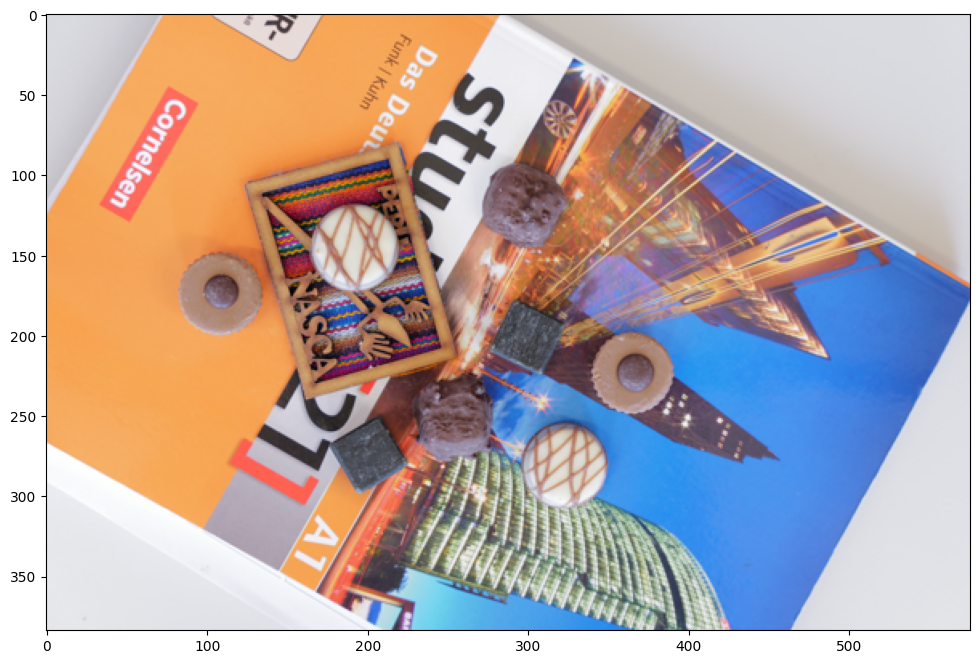

In [70]:
importlib.reload(utils)
from utils import *

save_gt_images(val_loader)

# Model :

# Loss :

# Csv file generation

In [11]:
# ============ TEST SETUP FOR SUBMISSION ============ #


test_dir = "../dataset_project_iapr2025/test"
test_files = sorted([f for f in os.listdir(test_dir) if f.endswith(".JPG")])

test_dataset = YOLOTestDataset(
	img_dir=test_dir,
	filenames=test_files,
	transform=test_transform
)

test_loader = torch.utils.data.DataLoader(
	test_dataset,
	batch_size=BATCH_SIZE,
	shuffle=False,
	pin_memory=True
)



NameError: name 'test_transform' is not defined

# Functions training and evaluation :

# Training :

In [ ]:
importlib.reload(utils)
from utils import *
# Creating the model from YOLOv3 class 
model = EfficientYOLO_12x18Grid().to(DEVICE) 
model = init_yolo_weights(model)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Nombre de paramètres entraînables : {num_params}")

# Defining the optimizer 
optimizer = optim.Adam(model.parameters(), lr = LEARNING_RATE) 

# Defining the loss function 
loss_fn = YOLOLoss() 


if LOAD_MODEL:
	load_checkpoint(CHECKPOINT_FILE, model, optimizer, LEARNING_RATE)
	
# Training the model
for e in range(1, NB_EPOCHS+1): 
	print("Epoch:", e) 
	training_loop(train_loader, model, optimizer, loss_fn, scaled_anchors=SCALED_ANCHORS, device=DEVICE) 

	# Validation
	val_loss = evaluate(val_loader, model, loss_fn, scaled_anchors=SCALED_ANCHORS, device=DEVICE)
	print(f"Validation Loss: {val_loss:.4f}")
	
	# Save validation images
	if e % 10 == 0:
    	save_val_images(model, val_loader, device=DEVICE, scaled_anchors=SCALED_ANCHORS, save_dir="val_images", epoch=e, class_names = CLASS_NAMES, grid_width=GRID_WIDTH, grid_height=GRID_HEIGHT, resized_img_width=RESIZED_IMG_WIDTH, resized_img_height=RESIZED_IMG_HEIGHT)

	# Saving the model 
	if SAVE_MODEL: 
		save_checkpoint(model, optimizer, filename=f"checkpoint.pth.tar")

# Generating the submission CSV file
generate_submission_csv_with_nms(
	model, 
	test_loader, 
	output_csv_path="output/test_submission.csv"
)


/home/IAPR/IAPR_Group_14/project/src/utils.py:402: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_file, map_location=DEVICE)


Nombre de paramètres entraînables : 8799362
==> Loading checkpoint
Epoch: 1


100%|██████████| 34/34 [00:10<00:00,  3.37it/s, loss=1.03]


Validation Loss: 0.6311
confidence max/min =  tensor(0.9211, device='cuda:0') tensor(2.0227e-12, device='cuda:0')
confidence max/min =  tensor(0.5731, device='cuda:0') tensor(3.3543e-09, device='cuda:0')
confidence max/min =  tensor(0.9041, device='cuda:0') tensor(2.2771e-11, device='cuda:0')
confidence max/min =  tensor(0.9052, device='cuda:0') tensor(1.9339e-10, device='cuda:0')
confidence max/min =  tensor(0.8953, device='cuda:0') tensor(5.7206e-11, device='cuda:0')
confidence max/min =  tensor(0.8610, device='cuda:0') tensor(1.3673e-11, device='cuda:0')
confidence max/min =  tensor(0.9321, device='cuda:0') tensor(1.2745e-09, device='cuda:0')
confidence max/min =  tensor(0.8543, device='cuda:0') tensor(5.0010e-11, device='cuda:0')
confidence max/min =  tensor(0.9150, device='cuda:0') tensor(7.0073e-11, device='cuda:0')
confidence max/min =  tensor(0.9734, device='cuda:0') tensor(4.3225e-12, device='cuda:0')
confidence max/min =  tensor(0.8948, device='cuda:0') tensor(4.5266e-09, dev

100%|██████████| 34/34 [00:06<00:00,  5.08it/s, loss=0.423]


Validation Loss: 0.5086
confidence max/min =  tensor(0.8487, device='cuda:0') tensor(7.1355e-09, device='cuda:0')
confidence max/min =  tensor(0.8251, device='cuda:0') tensor(2.1859e-10, device='cuda:0')
confidence max/min =  tensor(0.8257, device='cuda:0') tensor(1.2144e-09, device='cuda:0')
confidence max/min =  tensor(0.8928, device='cuda:0') tensor(2.1840e-11, device='cuda:0')
confidence max/min =  tensor(0.7858, device='cuda:0') tensor(3.6625e-08, device='cuda:0')
confidence max/min =  tensor(0.8079, device='cuda:0') tensor(7.3344e-11, device='cuda:0')
confidence max/min =  tensor(0.7996, device='cuda:0') tensor(2.1684e-10, device='cuda:0')
confidence max/min =  tensor(0.7634, device='cuda:0') tensor(3.0238e-11, device='cuda:0')
confidence max/min =  tensor(0.8517, device='cuda:0') tensor(1.5156e-09, device='cuda:0')
confidence max/min =  tensor(0.8366, device='cuda:0') tensor(2.7037e-09, device='cuda:0')
confidence max/min =  tensor(0.7757, device='cuda:0') tensor(9.6900e-11, dev

... (162 outputs left out)

100%|██████████| 34/34 [00:06<00:00,  5.12it/s, loss=0.0564]


Validation Loss: 0.8411
confidence max/min =  tensor(0.8504, device='cuda:0') tensor(6.9798e-12, device='cuda:0')
confidence max/min =  tensor(0.9036, device='cuda:0') tensor(4.6558e-12, device='cuda:0')
confidence max/min =  tensor(0.6924, device='cuda:0') tensor(5.1363e-12, device='cuda:0')
confidence max/min =  tensor(0.7165, device='cuda:0') tensor(3.0412e-12, device='cuda:0')
confidence max/min =  tensor(0.6983, device='cuda:0') tensor(9.7487e-12, device='cuda:0')
confidence max/min =  tensor(0.3120, device='cuda:0') tensor(1.9675e-10, device='cuda:0')
confidence max/min =  tensor(0.8266, device='cuda:0') tensor(1.0084e-11, device='cuda:0')
confidence max/min =  tensor(0.6999, device='cuda:0') tensor(1.2082e-13, device='cuda:0')
confidence max/min =  tensor(0.9087, device='cuda:0') tensor(4.2279e-11, device='cuda:0')
confidence max/min =  tensor(0.8934, device='cuda:0') tensor(1.6825e-12, device='cuda:0')
confidence max/min =  tensor(0.8576, device='cuda:0') tensor(1.7909e-11, dev

100%|██████████| 34/34 [00:06<00:00,  5.10it/s, loss=0.0612]


Validation Loss: 0.8370
confidence max/min =  tensor(0.8746, device='cuda:0') tensor(3.5730e-13, device='cuda:0')
confidence max/min =  tensor(0.8035, device='cuda:0') tensor(2.4216e-11, device='cuda:0')
confidence max/min =  tensor(0.7463, device='cuda:0') tensor(2.9144e-12, device='cuda:0')
confidence max/min =  tensor(0.7762, device='cuda:0') tensor(3.8374e-13, device='cuda:0')
confidence max/min =  tensor(0.8562, device='cuda:0') tensor(5.2992e-11, device='cuda:0')
confidence max/min =  tensor(0.7497, device='cuda:0') tensor(1.2431e-11, device='cuda:0')
confidence max/min =  tensor(0.8200, device='cuda:0') tensor(1.5094e-10, device='cuda:0')
confidence max/min =  tensor(0.8962, device='cuda:0') tensor(1.2732e-12, device='cuda:0')
confidence max/min =  tensor(0.7660, device='cuda:0') tensor(6.0310e-12, device='cuda:0')
confidence max/min =  tensor(0.7025, device='cuda:0') tensor(1.4389e-11, device='cuda:0')
confidence max/min =  tensor(0.7494, device='cuda:0') tensor(1.7883e-13, dev

# Check the transformations :

In [ ]:
def save_gt_images(loader, class_names=CLASS_NAMES, save_dir="gt_visualizations", grid_width=GRID_WIDTH, grid_height=GRID_HEIGHT):
	"""
	Saves images with ground truth bounding boxes from a DataLoader
	
	Args:
		loader: PyTorch DataLoader (train or val)
		class_names: List of class names
		save_dir: Directory to save visualized images
	"""
	os.makedirs(save_dir, exist_ok=True)
	print(f"Saving ground truth images to {save_dir}/")
	# Color map for different classes
	colour_map = plt.get_cmap("tab20b")
	colors = [colour_map(i) for i in np.linspace(0, 1, len(class_names))]
	
	for batch_idx, (images, targets) in enumerate(tqdm(loader)):
		# Convert images from tensor to numpy and denormalize
		images = images.permute(0, 2, 3, 1).cpu().numpy() # shape (batch_size, channels, height, width) to (batch_size, height, width, channels)
		images = (images * 255).astype(np.uint8)
		
		# Process each image in the batch
		for img_idx in range(images.shape[0]):
			img = images[img_idx]
			fig, ax = plt.subplots(1, figsize=(12, 8))
			ax.imshow(img)
			
			# Get boxes from the unique scale
			all_boxes = []
			target = targets[img_idx]
			anchor_indices = torch.where(target[..., 0] == 1)  # Cells with objects
			
			for anchor, i, j in zip(*anchor_indices):
				# for ex anchor = 0, i = 7, j = 15
				# Get box coordinates : x,y in [0,1] relative to the cell, w,h in [0,grid_width-1] and [0, grid_height-1] so relative to the grid size
				x, y, w, h = target[anchor, i, j, 1:5]
				class_id = target[anchor, i, j, 5].int() # in [0, 12]
				
				
				# Calculate box coordinates normalized to [0,1] with respect to the resized image size
				x_center = (j + x) / grid_width # normalize to [0,1]
				y_center = (i + y) / grid_height
				width = w / grid_width
				height = h / grid_height

				all_boxes.append([
					class_id.item(),  # class
					1.0,             # confidence (ground truth so 1)
					x_center.item(),
					y_center.item(),
					width.item(),
					height.item()
				])
			
			print(len(all_boxes))
			
			# Draw all ground truth boxes
			for box in all_boxes:
				class_id, conf, x, y, w, h = box
				
				# Calculate coordinates
				x1 = (x - w/2) * img.shape[1] # finds the upper-left corner of the box in pixels
				y1 = (y - h/2) * img.shape[0]
				width = w * img.shape[1]
				height = h * img.shape[0]
				
				# Create rectangle patch
				rect = patches.Rectangle(
					(x1, y1), width, height,
					linewidth=2,
					edgecolor=colors[int(class_id)],
					facecolor="none"
				)
				ax.add_patch(rect)
				
				# Add label
				plt.text(
					x1, y1,
					s=f"{class_names[int(class_id)]} {conf:.2f}",
					color="white",
					verticalalignment="top",
					bbox={"color": colors[int(class_id)], "pad": 0},
				)
			
			# Save image
			plt.axis("off")
			plt.savefig(
				os.path.join(save_dir, f"img_{batch_idx + img_idx}.png"),
				bbox_inches="tight",
				pad_inches=0,
				dpi=100
			)
			plt.close()

# Usage example
save_gt_images(
   loader=val_loader,
   class_names=CLASS_NAMES,
   save_dir="train_gt_visualizations"
)
print(f"Saved ground truth visualizations to train_gt_visualizations/")


In [ ]:
len(train_loader)